In [11]:

import numpy as np
import matplotlib.pyplot as plt

def acceleration(x):
    return -x

def leapfrog(x, vhalf, h):
    vnewhalf = vhalf + h * acceleration(x)
    xnew = x + h * vnewhalf

    return xnew, vnewhalf


In [12]:
h = 0.1
t_end = 20.0
n_steps = int(round(t_end / h))

t = np.arange(n_steps + 1) * h
x = np.zeros(n_steps + 1)
v_half = np.zeros(n_steps)

x[0] = 0.5
v_minus = 0.0 - (h / 2) * acceleration(x[0])

for n in range(n_steps):
    x[n + 1], v_plus = leapfrog(x[n], v_minus, h)
    v_half[n] = v_plus
    v_minus = v_plus

t_half = t[:-1] + h / 2


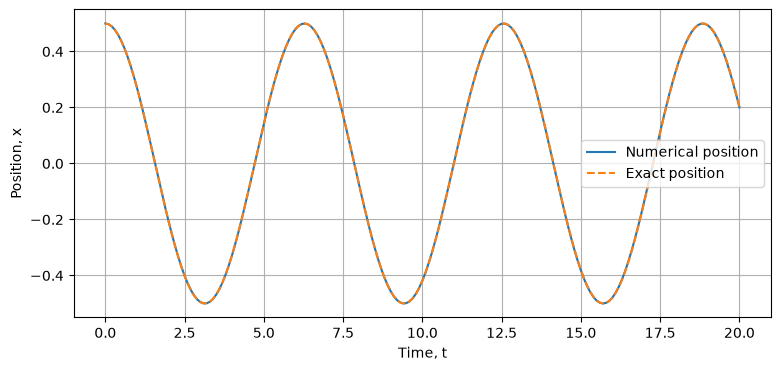

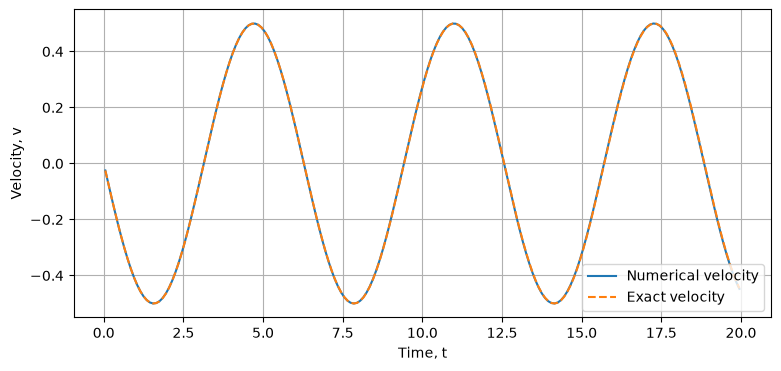

Maximum position error: 0.0038152808690173623
Maximum velocity error: 0.00393146012390859


In [13]:
plt.figure(figsize=(9, 4))
plt.plot(t, x, label="Numerical position")
plt.plot(t, 0.5*np.cos(t), "--", label="Exact position")
plt.xlabel("Time, t")
plt.ylabel("Position, x")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(t_half, v_half, label="Numerical velocity")
plt.plot(t_half, -0.5*np.sin(t_half), "--",
         label="Exact velocity")
plt.xlabel("Time, t")
plt.ylabel("Velocity, v")
plt.grid(True)
plt.legend()
plt.show()

print("Maximum position error:",
      np.max(np.abs(x - 0.5*np.cos(t))))

print("Maximum velocity error:",
      np.max(np.abs(v_half + 0.5*np.sin(t_half))))

In [14]:
def integrate(h, staggered=True, t_end=20.0):
    N = int(round(t_end / h))
    times = np.arange(N + 1) * h
    xs = np.zeros(N + 1)
    xs[0] = 0.5

    if staggered:
        v = -(h / 2) * acceleration(xs[0])
    else:
        v = 0.0

    for n in range(N):
        xs[n + 1], v = leapfrog(xs[n], v, h)

    return times, xs


hs = [0.2, 0.1, 0.05, 0.025]
for staggered in [True, False]:
    errors = []
    for h in hs:
        times, xs = integrate(h, staggered)
        error = np.max(np.abs(xs - 0.5*np.cos(times)))
        errors.append(error)

    print("\nStaggered start:", staggered)
    for i, h in enumerate(hs):
        if i == 0:
            print(h, errors[i], "none")
        else:
            p = np.log2(errors[i-1] / errors[i])
            print(h, errors[i], p)


Staggered start: True
0.2 0.015396153502616333 none
0.1 0.0038152808690173623 2.012708787512314
0.05 0.0009516945580628489 2.003218740978528
0.025 0.00023779054510253417 2.000807268990838

Staggered start: False
0.2 0.0645570937352627 none
0.1 0.028628279982487917 1.1731346377953331
0.05 0.013401662702342016 1.0950289918432259
0.025 0.0064754034102747 1.049370023471847


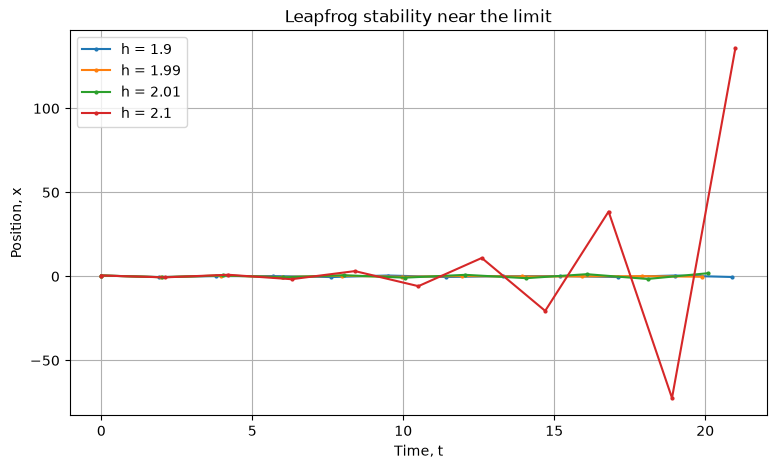

In [15]:
test_h = [1.9, 1.99, 2.01, 2.1]

plt.figure(figsize=(9, 5))

for h in test_h:
    times, xs = integrate(h, staggered=True)
    plt.plot(times, xs, "o-", markersize=2,
             label=f"h = {h}")

plt.xlabel("Time, t")
plt.ylabel("Position, x")
plt.title("Leapfrog stability near the limit")
plt.grid(True)
plt.legend()
plt.show()